In [165]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

In [2]:
# Data Ingestion, shape, info, tail
df = pd.read_csv ("Electric_Production.csv")
df.head()

,DATE,IPG2211A2N
0,1/1/1985,72.5052
1,2/1/1985,70.6720
2,3/1/1985,62.4502
3,4/1/1985,57.4714
4,5/1/1985,55.3151


In [3]:
df. shape

(397, 2)

In [4]:
df. info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   DATE        397 non-null    str    
 1   IPG2211A2N  397 non-null    float64
dtypes: float64(1), str(1)
memory usage: 9.5 KB


In [5]:
#Rename the columns & convert DATE to a real date
df.rename(columns= {"DATE": "date", "IPG2211A2N":"production"}, inplace = True)
df.head()

,date,production
0,1/1/1985,72.5052
1,2/1/1985,70.6720
2,3/1/1985,62.4502
3,4/1/1985,57.4714
4,5/1/1985,55.3151


In [6]:
# converting the date type to a real date
df["date"]= pd.to_datetime(df["date"], format= "%m/%d/%Y")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        397 non-null    datetime64[us]
 1   production  397 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 6.3 KB


In [7]:
# make the date the index & sort by time
df = df.set_index("date").sort_index()
df= df.asfreq("MS")
df.head

<bound method NDFrame.head of             production
date                  
1985-01-01     72.5052
1985-02-01     70.6720
1985-03-01     62.4502
1985-04-01     57.4714
1985-05-01     55.3151
...                ...
2017-09-01     98.6154
2017-10-01     93.6137
2017-11-01     97.3359
2017-12-01    114.7212
2018-01-01    129.4048

[397 rows x 1 columns]>

In [11]:
# check for missing value, duplicate & gap\
df.isnull ().sum()
df.duplicated().sum()

min_date = df.index.min()
max_date= df.index.max()
date_range= pd.date_range(min_date, max_date, freq= "MS")

print(f" Expected Months: {len(date_range)} | Available Months {len(df)}")


 Expected Months: 397 | Available Months 397


In [12]:
#Since the dataset has no gap create one and find the gap
demo = df['production'].copy()
demo.iloc [[1,50,51]] = np.nan
demo

date
1985-01-01     72.5052
1985-02-01         NaN
1985-03-01     62.4502
1985-04-01     57.4714
1985-05-01     55.3151
                ...   
2017-09-01     98.6154
2017-10-01     93.6137
2017-11-01     97.3359
2017-12-01    114.7212
2018-01-01    129.4048
Freq: MS, Name: production, Length: 397, dtype: float64

In [16]:
# To repair and cal for the gap
repair = demo.interpolate(method = "time")

pd.DataFrame({
    "repaired": repair.iloc[[1,50,51]],
    "Actual": df['production'].iloc [[1,50,51]]
}).round(2)

,repaired,Actual
date,,
1985-02-01,67.22,70.67
1989-03-01,72.59,73.35
1989-04-01,68.07,65.11


<Axes: ylabel='production'>

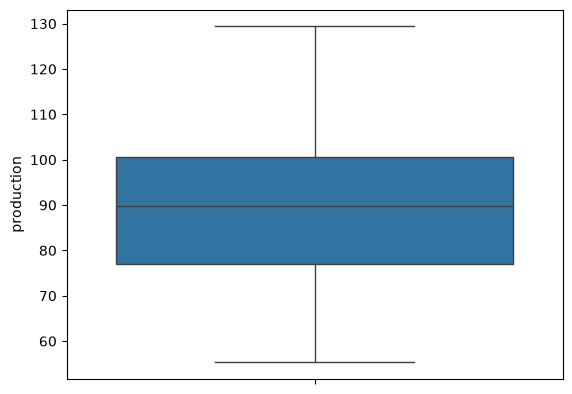

In [17]:
#check for outliers

sns.boxplot(df['production'])

In [19]:
# to calculate IQR

Q3 = demo.quantile (0.75)
Q1 = demo.quantile (0.25)
IQR = Q3 - Q1
lower_bound = Q1- 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Acceptable values must be in a range {lower_bound:.1f} to {upper_bound:.1f}")

Acceptable values must be in a range 42.3 to 135.7


In [23]:
demo[(demo.values < 41.9) | (demo.values > 136.2)]

Series([], Freq: MS, Name: production, dtype: float64)

In [25]:
df.head()

,production
date,
1985-01-01,72.5052
1985-02-01,70.6720
1985-03-01,62.4502
1985-04-01,57.4714
1985-05-01,55.3151


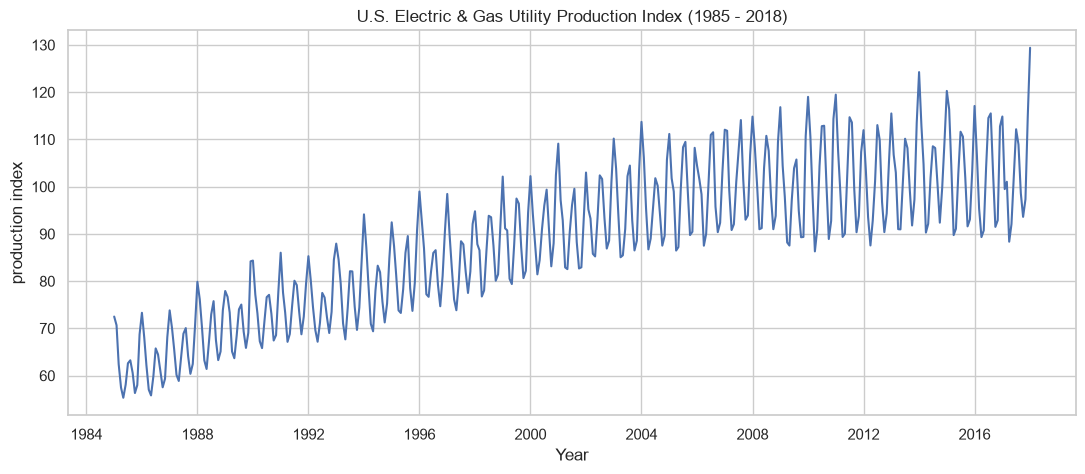

In [28]:
#exploration & time series decomposition

plt.figure(figsize = (13, 5))
sns.set_theme(style = "whitegrid")

sns.lineplot(data= df, x= df.index, y= df['production'])
plt.title("U.S. Electric & Gas Utility Production Index (1985 - 2018)")
plt.xlabel("Year")
plt.ylabel("production index")
plt.show ()

C:\Users\kazee\AppData\Local\Temp\ipykernel_34488\3188980764.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend(title= "Year")


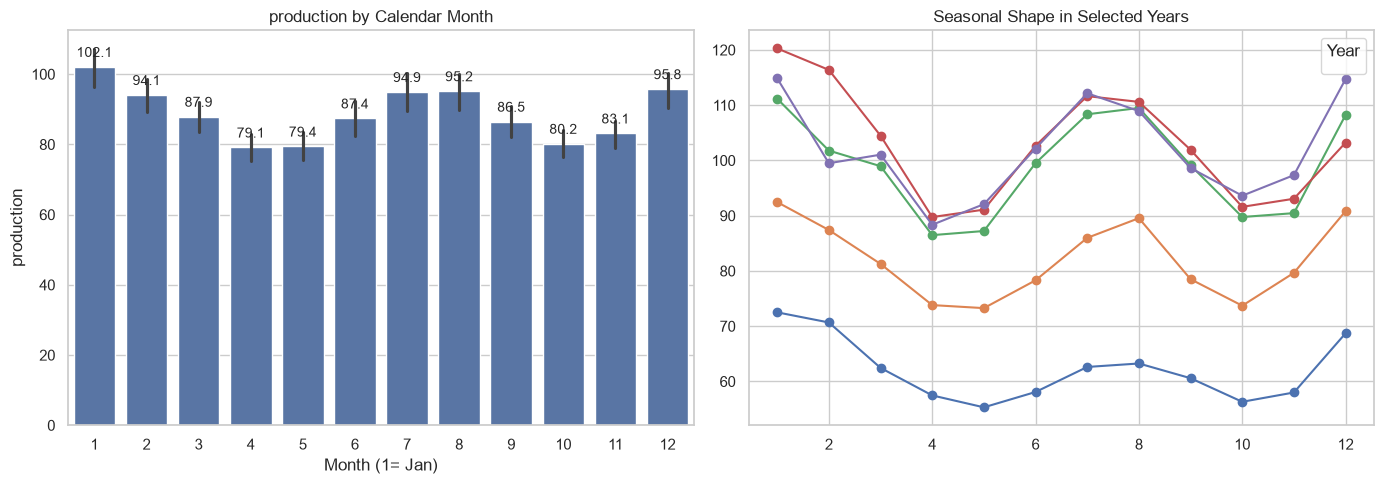

In [52]:
#which months has the highest production
fig, ax = plt.subplots(1,2, figsize = (14, 5))
barplot = sns.barplot( data= df, x= df.index.month, y= df['production'], ax = ax[0])
ax[0].set_title("production by Calendar Month")
ax[0].set_xlabel("Month (1= Jan)")

ax[0].bar_label(ax[0].containers[0], fmt= "%.1f", fontsize = 10, padding = 5)
pivot = df.pivot_table (index = df.index.month, columns = df.index.year, values= "production")

for year in [1985, 1995, 2005, 2015, 2017]:
    ax[1].plot (pivot.index, pivot[year], marker = "o")
ax[1].set_title ("Seasonal Shape in Selected Years")
ax[1].legend(title= "Year")

plt.tight_layout()
plt.show()


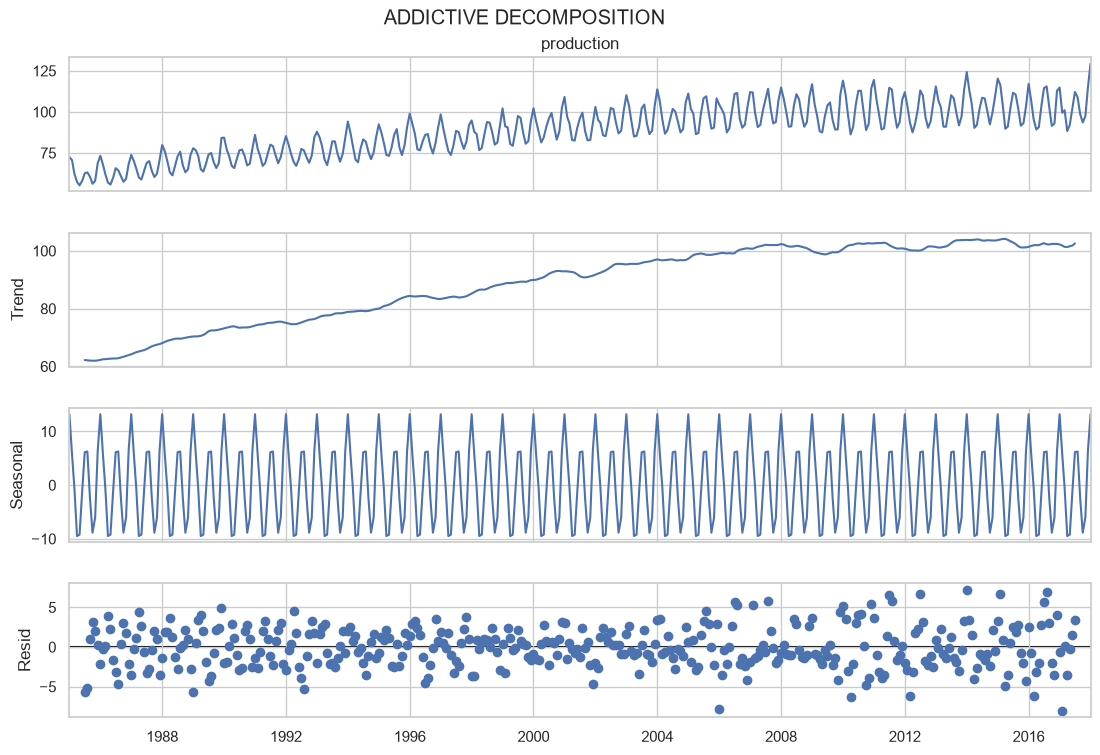

In [76]:
# Time Series Decomposition - Addictive & Multiplicative model
decomp_add = seasonal_decompose (df['production'], model = "additive", period = 12)
decomp_mult = seasonal_decompose (df['production'], model = "multiplicative", period = 12)

# Addictive model
fig = decomp_add.plot()
fig.set_size_inches(12, 8)
fig.suptitle("ADDICTIVE DECOMPOSITION")
plt.show()

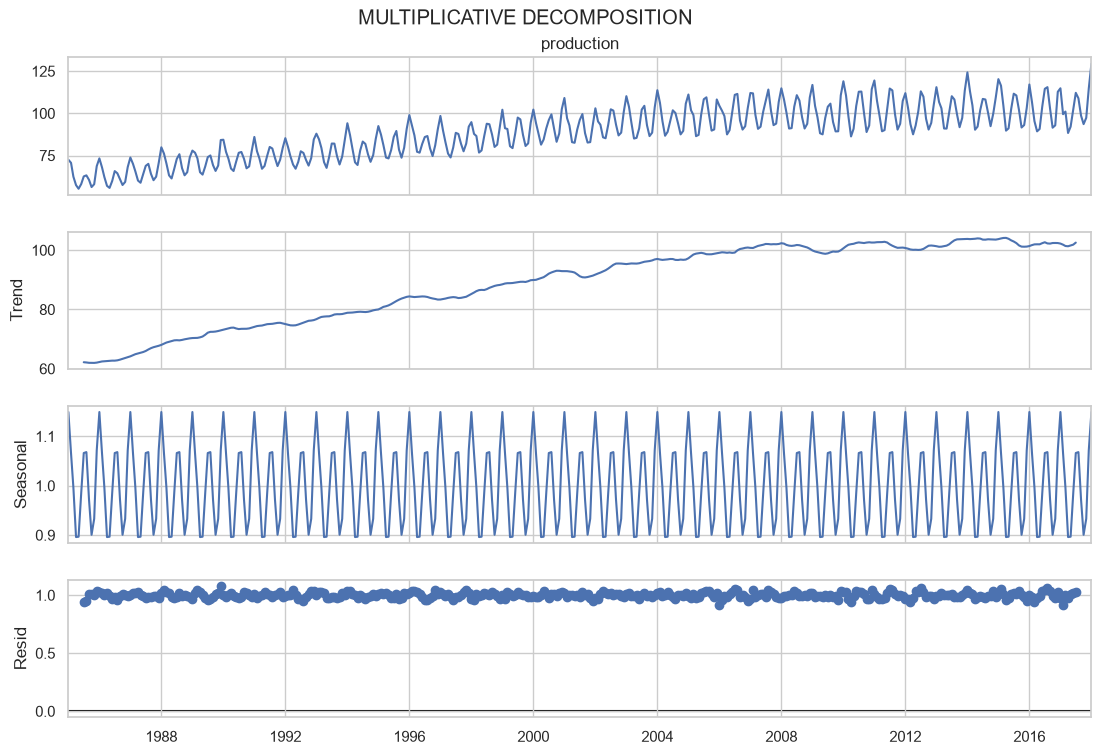

In [77]:
# Multiplicative model
fig = decomp_mult.plot()
fig.set_size_inches(12, 8)
fig.suptitle("MULTIPLICATIVE DECOMPOSITION")
plt.show()

In [80]:
# To calculate for residual model
res_add = decomp_add.resid.dropna()
res_mult = decomp_add.resid.dropna()

# Relative residual spread
rel_add = res_add.std() / df ['production'].mean() * 100
rel_mult = res_mult.std() * 100
print(f"Additive Residual Spread: { rel_add:.2f}%")
print(f"Multiplicative Residual Spread: { rel_mult:.2f}%")

Additive Residual Spread: 2.92%
Multiplicative Residual Spread: 259.40%


In [81]:
# To determine a stationary time series decomposition
stat, p_value, *_ = adfuller (df['production'])

In [82]:
stat

np.float64(-2.25699035004724)

In [83]:
p_value

np.float64(0.18621469116586942)

In [85]:
### Model selection and training
# train & test split
df['production'].shape


(397,)

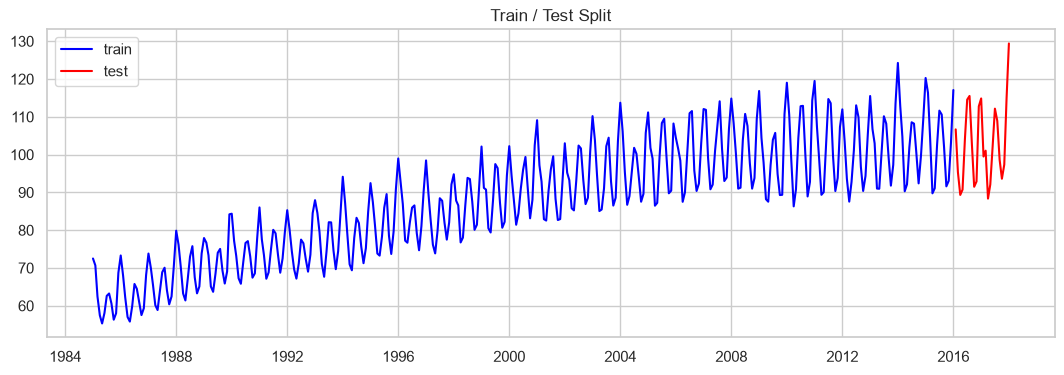

In [95]:
train = df['production'].iloc[:-24] # 373 records split
test = df['production'].iloc[-24:] # 24 records split

fig, ax= plt.subplots(figsize =(13, 4))
ax.plot (train, label ="train", color="blue")
ax.plot (test, label ="test", color="red")
ax.set_title("Train / Test Split")
ax.legend()
plt.show()

In [112]:
# baseline model - evaluation
def evaluate (y_true, y_pred, name):
    mae = mean_absolute_error ( y_true, y_pred)
    rmse = root_mean_squared_error (y_true, y_pred)
    mape = mean_absolute_percentage_error (y_true, y_pred) * 100
    return {
    "Model": name,
    "MAE": mae,
    "RMSE":rmse,
    "MAPE":mape
    }

forecasts= {}
scores = []

def record (name, preds):
    preds = pd.Series (np.asarray(preds), index= test.index)
    forecasts[name] = preds
    scores.append (evaluate(test, preds, name))
    s= scores [-1]
    print(f"{name} : MAE= {s ['MAE']:.2F} | RMSE= {s ['RMSE']:.2F} | MAPE= {s ['MAPE']:.2F}%")

In [113]:
naive_pred = np.repeat (train.iloc[-1], 24)
record("Naive", naive_pred)

Naive : MAE= 15.24 | RMSE= 17.64 | MAPE= 15.75%


In [122]:
seasonal_naive_pred = np.tile(train.iloc[-12:].values, 24 // 12 + 1) [:24]
record ("seasonal Naive", seasonal_naive_pred)

seasonal Naive : MAE= 4.19 | RMSE= 6.22 | MAPE= 3.92%


In [148]:
df['production'].shape

(397,)

In [151]:
test_month = 24
train = df.iloc[:-24] 
test = df.iloc[-24:]


print(f"Training set: {train.index.min().strftime('%Y-%m-%d')} to {train.index.max().strftime('%Y-%m-%d')} ({len(train)} observations)")
print(f"Testing set: {test.index.min().strftime('%Y-%m-%d')} to {test.index.max().strftime('%Y-%m-%d')} ({len(test)} observations)")

Training set: 1985-01-01 to 2016-01-01 (373 observations)
Testing set: 2016-02-01 to 2018-01-01 (24 observations)


In [176]:
#SARMAX
model = SARIMAX(
    train["production"],
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity= False,
    enforce_invertibility= False
)


sarima_fit= model.fit()
print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         production   No. Observations:                  373
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -782.819
Date:                            Mon, 19 Oct 2026   AIC                           1575.637
Time:                                    02:03:28   BIC                           1594.870
Sample:                                01-01-1985   HQIC                          1583.296
                                     - 01-01-2016                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5234      0.052      9.985      0.000       0.421       0.626
ma.L1         -0.9522      0.020   

In [167]:

### Evaluation & Reporting

In [173]:
# forecast over the test set
forecast_res = sarima_fit.get_forecast(steps=len(test))
forecast_df = forecast_res.summary_frame()

#compute the accuracy metrics
y_true = test ['production']
y_pred = forecast_df ['mean']

mae = mean_absolute_error ( y_true, y_pred)
rmse = np.sqrt(root_mean_squared_error (y_true, y_pred))
mape = mean_absolute_percentage_error (y_true, y_pred) 

print("-----Model Evaluation Metrics-----")
print(f"MAE : {mae:.2F}")
print(f"RMSE : {rmse:.2F}")
print(f"MAPE : {mape *100:.2F} %") 

-----Model Evaluation Metrics-----
MAE : 3.17
RMSE : 2.07
MAPE : 3.00 %


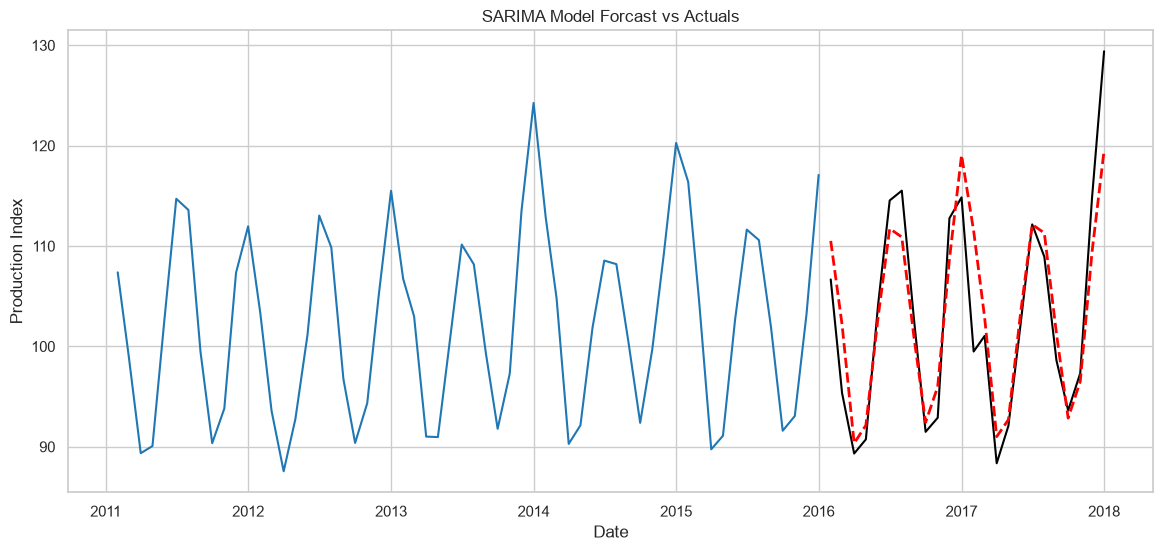

In [177]:
#Plot a graph
plt.figure(figsize= (14,6))
plt.plot(train.index[-60:], train['production'][-60:], label = "Historical Train Data (last 5 year)", color = "#1f77b4")
plt.plot(test.index, y_true, label = "Actual test Values", color = "black")
plt.plot(test.index, y_pred, label = "SARIMA Forcast", color = "red", linestyle= "--", linewidth = 2)

plt.title("SARIMA Model Forcast vs Actuals")
plt.xlabel("Date")
plt.ylabel("Production Index")
plt.show()

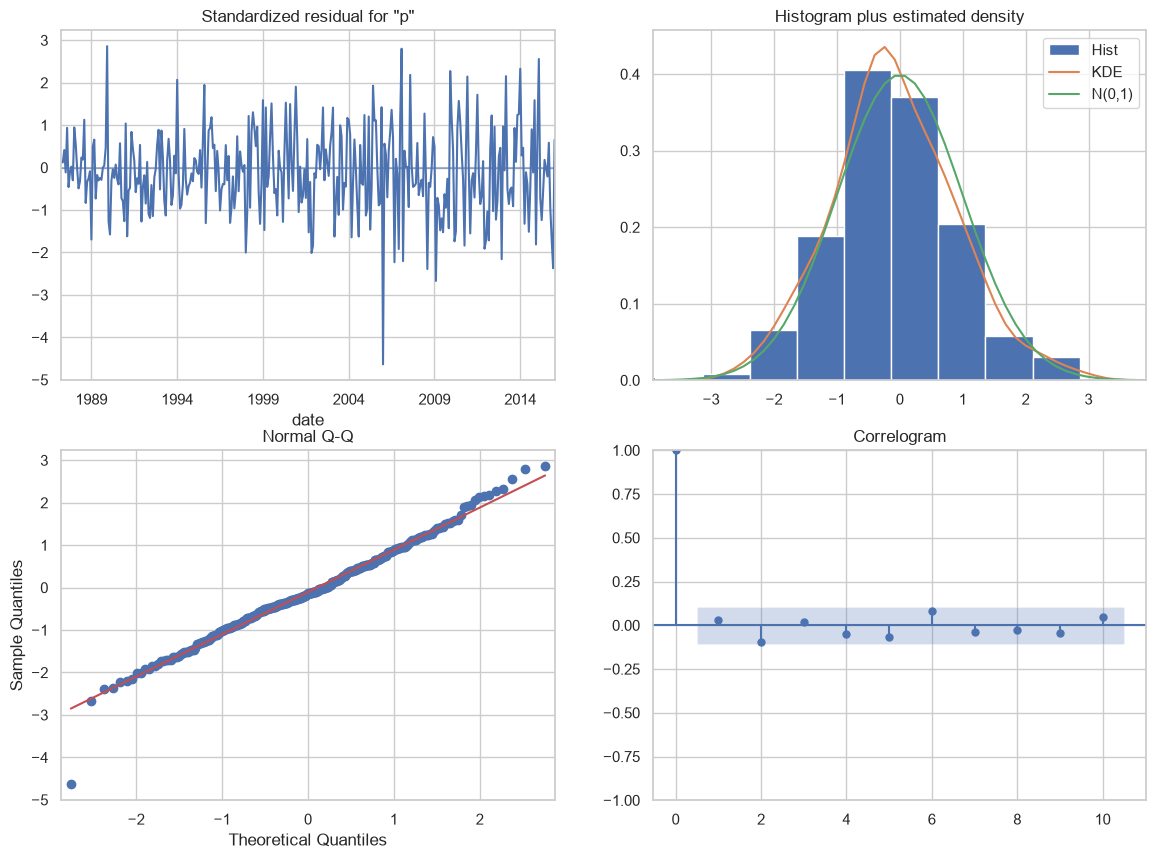

In [185]:
# Visualize Residual Diagnostics
sarima_fit.plot_diagnostics( figsize=(14, 10))
plt.show()

In [186]:
# Future Forecast
final_model = SARIMAX(
    df['production'],
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity= False,
    enforce_invertibility= False
)
final_fit = final_model.fit()
print (final_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         production   No. Observations:                  397
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -858.546
Date:                            Mon, 19 Oct 2026   AIC                           1727.092
Time:                                    03:08:05   BIC                           1746.659
Sample:                                01-01-1985   HQIC                          1734.864
                                     - 01-01-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5234      0.046     11.370      0.000       0.433       0.614
ma.L1         -0.9540      0.018   

In [188]:
#Forecast 12 months into the future
future_forecast = final_fit.get_forecast (steps= 12)
future_df = future_forecast.summary_frame()

future_df

production,mean,mean_se,mean_ci_lower,mean_ci_upper
2018-02-01,114.273570,2.442782,109.485805,119.061334
2018-03-01,105.022000,2.810940,99.512659,110.531342
2018-04-01,92.706756,2.933811,86.956592,98.456919
2018-05-01,94.098591,2.985287,88.247537,99.949645
2018-06-01,104.635077,3.012121,98.731429,110.538726
2018-07-01,113.870454,3.029308,107.933119,119.807789
2018-08-01,112.709170,3.042306,106.746360,118.671979
2018-09-01,102.020680,3.053336,96.036251,108.005108
2018-10-01,93.916300,3.063390,87.912167,99.920434
2018-11-01,97.170745,3.072939,91.147896,103.193594


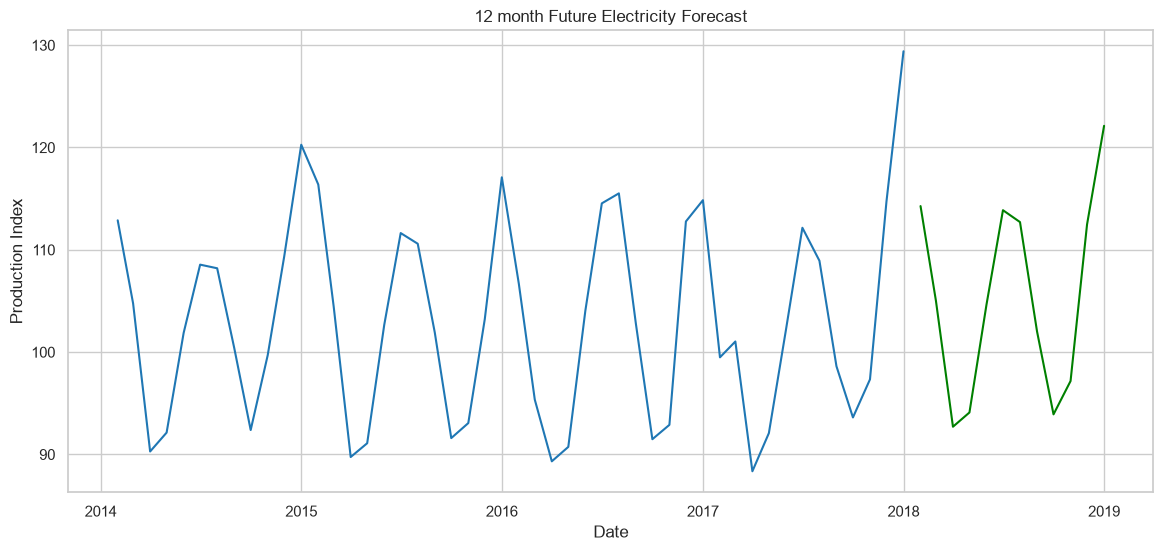

In [194]:
# visualize the Forecasted Future
plt.figure(figsize= (14,6))
plt.plot(df.index[-48:], df['production'][-48:], label = "Historical Observe Data", color = "#1f77b4")
plt.plot(future_df.index, future_df['mean'], label = "12 month Future Forecast", color = "green")

plt.title("12 month Future Electricity Forecast")
plt.xlabel("Date")
plt.ylabel("Production Index")
plt.show()

In [200]:
summary_table = pd.DataFrame({
    "Forecasted Production": future_df['mean'].round(2),
    "Lower CI (95%)" :  future_df['mean_ci_lower'].round(2),
    "Upper CI (95%)" :  future_df['mean_ci_upper'].round(2)
})

summary_table

,Forecasted Production,Lower CI (95%),Upper CI (95%)
2018-02-01,114.27,109.49,119.06
2018-03-01,105.02,99.51,110.53
2018-04-01,92.71,86.96,98.46
2018-05-01,94.10,88.25,99.95
2018-06-01,104.64,98.73,110.54
2018-07-01,113.87,107.93,119.81
2018-08-01,112.71,106.75,118.67
2018-09-01,102.02,96.04,108.01
2018-10-01,93.92,87.91,99.92
2018-11-01,97.17,91.15,103.19
